# EnSurv: Simulations for Asymptotic Properties

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
 
_PALETTE = ["#1b3a5c", "#c0442c", "#3f8f6f", "#8a6bb1", "#c99a2e", "#4a7fa8",
            "#9c5a2e", "#5a5a5a", "#2e7d7d", "#a13d63"]
 
 
def set_journal_style():
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 10.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#333333",
        "axes.labelcolor": "#1a1a1a",
        "axes.titlesize": 11.5,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linewidth": 0.5,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
    })

set_journal_style()

Device: cuda:0
Fixed c0=0.367879, tau=7.389056
Population P(Y >= tau)=0.031295
Query: c=0.606531, u=0.200000
Population Psi(c,u)=1.05019442
Fixed grid: 66 censoring times x 66 u values
Repetitions=50, bootstrap replicates B=50

n=100    mean=1.056070 | point MAE=0.113936 | mean grid error=0.236500 | no-followup datasets=0/50
n=500    mean=1.064466 | point MAE=0.047751 | mean grid error=0.108302 | no-followup datasets=0/50
n=1000   mean=1.052481 | point MAE=0.029286 | mean grid error=0.068332 | no-followup datasets=0/50
n=2000   mean=1.048343 | point MAE=0.019508 | mean grid error=0.047442 | no-followup datasets=0/50
n=5000   mean=1.043676 | point MAE=0.016540 | mean grid error=0.036692 | no-followup datasets=0/50
n=10000  mean=1.052140 | point MAE=0.012370 | mean grid error=0.025006 | no-followup datasets=0/50
n=20000  mean=1.049344 | point MAE=0.007353 | mean grid error=0.016138 | no-followup datasets=0/50
n=30000  mean=1.051869 | point MAE=0.006502 | mean grid error=0.013859 | no-fol

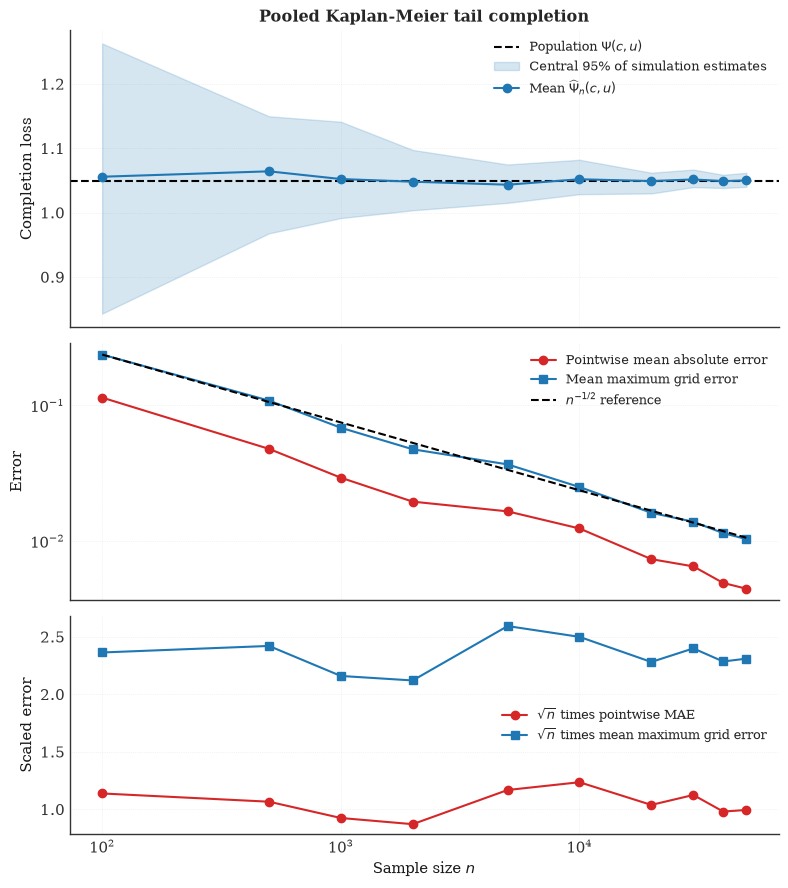

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import norm

from ensurv.km import (
    kaplan_meier_batched,
    km_survival_at_vec,
    compute_psi_hat_vec,
)


# Fixed design parameters: do not change them with sample size.
BETA_GEN = np.array([1.5, -1.0, 0.5, 0.8, -0.2], dtype=float)
SIGMA_Z = 1.0
CENSOR_LOG_SD = 2.0

C0 = float(np.exp(-1.0))
TAU = float(np.exp(2.0))

# Retain the original query point.
QUERY_C = float(np.exp(-0.5))
QUERY_U = 0.2

# Fixed grids, augmented to contain the exact query point.
GRID_SIZE = 65


def population_psi(c_values, u_values, tau, mu, sigma):
    """
    Exact normal-distribution reference for horizon-restricted completion.

    Returns an array of shape (number of censoring times, number of u values).

    Psi(c,u) =
        [integral_{log(c)}^{log(tau)} |z-u| f_Z(z) dz
         + |log(tau)-u| P(Z >= log(tau))]
        / P(Z > log(c)).

    The integral is evaluated analytically using normal interval probabilities
    and first moments. No unbounded-tail quadrature is used.
    """
    c_values = np.asarray(c_values, dtype=np.float64)
    u_values = np.asarray(u_values, dtype=np.float64)

    if c_values.ndim != 1 or u_values.ndim != 1:
        raise ValueError("c_values and u_values must be one-dimensional.")
    if not np.isfinite(c_values).all() or not np.isfinite(u_values).all():
        raise ValueError("Query values must be finite.")
    if not np.isfinite(tau) or tau <= 0:
        raise ValueError("tau must be finite and positive.")
    if (c_values <= 0).any() or (c_values >= tau).any():
        raise ValueError("Every censoring query must satisfy 0 < c < tau.")
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma must be finite and positive.")

    lower = np.log(c_values)[:, None]
    upper = np.log(tau)
    u = u_values[None, :]

    # Split the absolute-value integral at u, clipped to the integration interval.
    split = np.clip(u, lower, upper)

    alpha = (lower - mu) / sigma
    gamma = (split - mu) / sigma
    omega = (upper - mu) / sigma

    # Probabilities of the left and right integration intervals.
    p_left = norm.sf(alpha) - norm.sf(gamma)
    p_right = norm.sf(gamma) - norm.sf(omega)

    # Integral z*f_Z(z) dz over each interval.
    first_left = (
        mu * p_left
        + sigma * (norm.pdf(alpha) - norm.pdf(gamma))
    )
    first_right = (
        mu * p_right
        + sigma * (norm.pdf(gamma) - norm.pdf(omega))
    )

    continuous_part = (
        u * p_left - first_left
        + first_right - u * p_right
    )
    terminal_part = np.abs(upper - u) * norm.sf(omega)
    denominator = norm.sf(alpha)

    if (denominator <= 0).any():
        raise FloatingPointError(
            "Population tail probability underflowed; adjust query parameters."
        )

    # Remove possible negative roundoff at zero.
    numerator = np.maximum(continuous_part + terminal_part, 0.0)
    return numerator / denominator


def estimate_psi_grid(km_curves, censor_times, predictions, tau):
    """
    Average individually normalized completion losses across bootstrap curves.

    Uses exactly the completion functions from EnSurv_Code.py, including
    its point-mass-at-tau fallback when a KM denominator is zero.
    """
    total = torch.zeros_like(predictions, dtype=torch.float64)
    zero_denominators = 0

    for km in km_curves:
        denominators = km_survival_at_vec(km, censor_times)
        zero_denominators += int((denominators <= 0).sum().item())

        total += compute_psi_hat_vec(
            predictions=predictions,
            km_time=km["time"],
            km_weight=km["weight"],
            censor_times=censor_times,
            denoms=denominators,
            tau=tau,
        )

    estimate = (total / len(km_curves)).cpu().numpy()
    fallback_fraction = zero_denominators / (
        len(km_curves) * len(censor_times)
    )
    return estimate, fallback_fraction


def run_simulation(
    sample_sizes=(100, 500, 1000, 2000, 5000, 10000,
                  20000, 30000, 40000, 50000),
    n_repetitions=50,
    B=50,
    seed=42,
    device=None,
    km_batch_size=4,
):
    """
    Fixed-horizon simulation of pooled KM tail-completion convergence.

    No model is trained: the object studied is the completion estimator.
    All datasets are retained, including those without follow-up reaching tau.
    """
    sample_sizes = np.asarray(sample_sizes, dtype=int)
    if sample_sizes.ndim != 1 or (sample_sizes < 1).any():
        raise ValueError("sample_sizes must contain positive integers.")
    if (np.diff(sample_sizes) <= 0).any():
        raise ValueError("sample_sizes must be strictly increasing.")
    if n_repetitions < 2 or B < 1 or km_batch_size < 1:
        raise ValueError(
            "Require n_repetitions >= 2, B >= 1 and km_batch_size >= 1."
        )
    if not (0 < C0 <= QUERY_C < TAU):
        raise ValueError("Require 0 < C0 <= QUERY_C < TAU.")

    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)

    # Separate reproducible streams for data generation and bootstrap sampling.
    data_seed, bootstrap_seed = np.random.SeedSequence(seed).spawn(2)
    data_rng = np.random.default_rng(data_seed)
    bootstrap_rng = np.random.default_rng(bootstrap_seed)

    mu_marg = 0.0
    sigma_marg = np.sqrt(np.dot(BETA_GEN, BETA_GEN) + SIGMA_Z**2)
    a = np.log(TAU)

    c_grid = np.exp(
        np.linspace(np.log(C0), a, GRID_SIZE + 1)[:-1]
    )
    c_grid[0] = C0
    c_grid = np.unique(np.append(c_grid, QUERY_C))

    u_grid = np.unique(
        np.append(np.linspace(np.log(C0), a, GRID_SIZE), QUERY_U)
    )

    query_c_index = int(np.searchsorted(c_grid, QUERY_C))
    query_u_index = int(np.searchsorted(u_grid, QUERY_U))

    truth_grid = population_psi(
        c_grid, u_grid, tau=TAU, mu=mu_marg, sigma=sigma_marg
    )
    point_truth = float(truth_grid[query_c_index, query_u_index])

    # Since T and C are independent, this is P(Y >= tau).
    followup_probability = (
        norm.sf((a - mu_marg) / sigma_marg)
        * norm.sf(np.log(TAU - C0) / CENSOR_LOG_SD)
    )

    shape = (len(sample_sizes), n_repetitions)
    point_estimates = np.empty(shape, dtype=np.float64)
    grid_errors = np.empty(shape, dtype=np.float64)
    fallback_fractions = np.empty(shape, dtype=np.float64)
    followup_counts = np.empty(shape, dtype=np.int64)

    censor_times = torch.as_tensor(
        c_grid, dtype=torch.float64, device=device
    )
    predictions = torch.as_tensor(
        u_grid, dtype=torch.float64, device=device
    )[None, :].expand(len(c_grid), -1)

    print(f"Device: {device}")
    print(f"Fixed c0={C0:.6f}, tau={TAU:.6f}")
    print(f"Population P(Y >= tau)={followup_probability:.6f}")
    print(f"Query: c={QUERY_C:.6f}, u={QUERY_U:.6f}")
    print(f"Population Psi(c,u)={point_truth:.8f}")
    print(f"Fixed grid: {len(c_grid)} censoring times x {len(u_grid)} u values")
    print(f"Repetitions={n_repetitions}, bootstrap replicates B={B}\n")

    with torch.inference_mode():
        for size_index, n in enumerate(sample_sizes):
            for repetition in range(n_repetitions):
                X = data_rng.normal(size=(n, len(BETA_GEN)))
                epsilon = data_rng.normal(scale=SIGMA_Z, size=n)
                Z = X @ BETA_GEN + epsilon
                T = np.exp(Z)

                # C >= c0 almost surely, independently of (X,T).
                censor_noise = data_rng.normal(
                    scale=CENSOR_LOG_SD, size=n
                )
                C = C0 + np.exp(censor_noise)

                Y = np.minimum(T, C)
                delta = (T <= C).astype(np.int64)

                followup_counts[size_index, repetition] = np.count_nonzero(
                    Y >= TAU
                )

                indices = bootstrap_rng.integers(
                    0, n, size=(B, n), dtype=np.int64
                )

                # ORIGINAL outcomes enter KM; the same fixed tau closes
                # every bootstrap curve.
                km_curves = kaplan_meier_batched(
                    Y,
                    delta,
                    indices,
                    close_tail=True,
                    device=device,
                    tau=TAU,
                    bootstrap_batch_size=km_batch_size,
                )

                estimated_grid, fallback_fraction = estimate_psi_grid(
                    km_curves, censor_times, predictions, tau=TAU
                )

                point_estimates[size_index, repetition] = estimated_grid[
                    query_c_index, query_u_index
                ]
                grid_errors[size_index, repetition] = np.max(
                    np.abs(estimated_grid - truth_grid)
                )
                fallback_fractions[size_index, repetition] = fallback_fraction

                del km_curves

            point_error = point_estimates[size_index] - point_truth
            print(
                f"n={n:<6d} "
                f"mean={point_estimates[size_index].mean():.6f} | "
                f"point MAE={np.abs(point_error).mean():.6f} | "
                f"mean grid error={grid_errors[size_index].mean():.6f} | "
                f"no-followup datasets="
                f"{np.count_nonzero(followup_counts[size_index] == 0)}"
                f"/{n_repetitions}"
            )

    return {
        "sample_sizes": sample_sizes,
        "point_estimates": point_estimates,
        "grid_errors": grid_errors,
        "fallback_fractions": fallback_fractions,
        "followup_counts": followup_counts,
        "truth_grid": truth_grid,
        "point_truth": point_truth,
        "c_grid": c_grid,
        "u_grid": u_grid,
        "c0": C0,
        "tau": TAU,
        "query_c": QUERY_C,
        "query_u": QUERY_U,
        "beta_gen": BETA_GEN,
        "sigma_z": SIGMA_Z,
        "censor_log_sd": CENSOR_LOG_SD,
        "followup_probability": followup_probability,
        "B": B,
        "seed": seed,
    }


def summarize_results(results):
    n = results["sample_sizes"]
    estimates = results["point_estimates"]
    errors = estimates - results["point_truth"]
    grid_errors = results["grid_errors"]

    return {
        "n": n,
        "point_mean": estimates.mean(axis=1),
        "point_sd": estimates.std(axis=1, ddof=1),
        "point_bias": errors.mean(axis=1),
        "point_mae": np.abs(errors).mean(axis=1),
        "point_rmse": np.sqrt(np.mean(errors**2, axis=1)),
        "point_q025": np.quantile(estimates, 0.025, axis=1),
        "point_q975": np.quantile(estimates, 0.975, axis=1),
        "mean_grid_error": grid_errors.mean(axis=1),
        "scaled_point_mae": np.sqrt(n) * np.abs(errors).mean(axis=1),
        "scaled_grid_error": np.sqrt(n) * grid_errors.mean(axis=1),
        "mean_fallback_fraction": results["fallback_fractions"].mean(axis=1),
        "no_followup_fraction": (
            results["followup_counts"] == 0
        ).mean(axis=1),
    }


def plot_convergence(results, summary):
    n = summary["n"]
    fig, axes = plt.subplots(
        3, 1, figsize=(8, 9), sharex=True,
        gridspec_kw={"height_ratios": [1.5, 1.3, 1.1]},
    )

    axes[0].axhline(
        results["point_truth"], color="black", linestyle="--",
        linewidth=1.5, label=r"Population $\Psi(c,u)$",
    )
    axes[0].fill_between(
        n, summary["point_q025"], summary["point_q975"],
        color="#1f77b4", alpha=0.18,
        label="Central 95% of simulation estimates",
    )
    axes[0].plot(
        n, summary["point_mean"], "o-", color="#1f77b4",
        label=r"Mean $\widehat{\Psi}_n(c,u)$",
    )
    axes[0].set_ylabel("Completion loss")
    axes[0].set_title("Pooled Kaplan-Meier tail completion")
    axes[0].legend(frameon=False)

    axes[1].plot(
        n, summary["point_mae"], "o-", color="#d62728",
        label="Pointwise mean absolute error",
    )
    axes[1].plot(
        n, summary["mean_grid_error"], "s-", color="#1f77b4",
        label="Mean maximum grid error",
    )

    # Visual rate guide, anchored at the first grid-error value.
    # It is not an estimated rate or confidence bound.
    reference = summary["mean_grid_error"][0] * np.sqrt(n[0] / n)
    axes[1].plot(
        n, reference, "--", color="black",
        label=r"$n^{-1/2}$ reference",
    )
    axes[1].set_yscale("log")
    axes[1].set_ylabel("Error")
    axes[1].legend(frameon=False)

    axes[2].plot(
        n, summary["scaled_point_mae"], "o-", color="#d62728",
        label=r"$\sqrt{n}$ times pointwise MAE",
    )
    axes[2].plot(
        n, summary["scaled_grid_error"], "s-", color="#1f77b4",
        label=r"$\sqrt{n}$ times mean maximum grid error",
    )
    axes[2].set_ylabel("Scaled error")
    axes[2].set_xlabel(r"Sample size $n$")
    axes[2].legend(frameon=False)
    axes[2].set_xscale("log")

    for axis in axes:
        axis.grid(True, linestyle=":", alpha=0.45)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    fig.tight_layout()
    fig.savefig("Theorem_1_simulations.pdf", bbox_inches="tight")
    fig.savefig("Theorem_1_simulations.png", dpi=300, bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    results = run_simulation(
        n_repetitions=50,
        B=50,
        seed=42,
        device="cuda:0",          # Automatic GPU/CPU selection; or use "cuda:0".
        km_batch_size=1000,
    )
    summary = summarize_results(results)

    np.savez_compressed("Theorem_1_raw_results.npz", **results)

    columns = list(summary)
    np.savetxt(
        "Theorem_1_summary.csv",
        np.column_stack([summary[name] for name in columns]),
        delimiter=",",
        header=",".join(columns),
        comments="",
        fmt="%.10g",
    )

    plot_convergence(results, summary)

Reference orders=(40, 64, 48): mass error=1.290e-07, refinement difference=inf, omitted-tail bound=7.458e-12
Reference orders=(80, 128, 96): mass error=2.932e-07, refinement difference=1.674e-04, omitted-tail bound=7.458e-12
Reference orders=(160, 256, 192): mass error=1.427e-08, refinement difference=1.963e-06, omitted-tail bound=7.458e-12

Device: cuda:0
Fixed c0=0.367879, tau=7.389056
Population P(Y >= tau)=0.022037
Fixed m=50, B=25, repetitions=10



/tmp/ipykernel_243236/1472425899.py:244: UserWarning: Reference stability goal was not reached. Increase REFERENCE_ORDERS before interpreting small discrepancies.
  warnings.warn(


n=100:   0%|          | 0/10 [00:00<?, ?it/s]

n=100    mean maximum grid error=0.101014 | no-followup datasets=2/10


n=500:   0%|          | 0/10 [00:00<?, ?it/s]

n=500    mean maximum grid error=0.047164 | no-followup datasets=0/10


... (2 outputs left out)

n=2000:   0%|          | 0/10 [00:00<?, ?it/s]

n=2000   mean maximum grid error=0.025319 | no-followup datasets=0/10


n=5000:   0%|          | 0/10 [00:00<?, ?it/s]

n=5000   mean maximum grid error=0.012400 | no-followup datasets=0/10


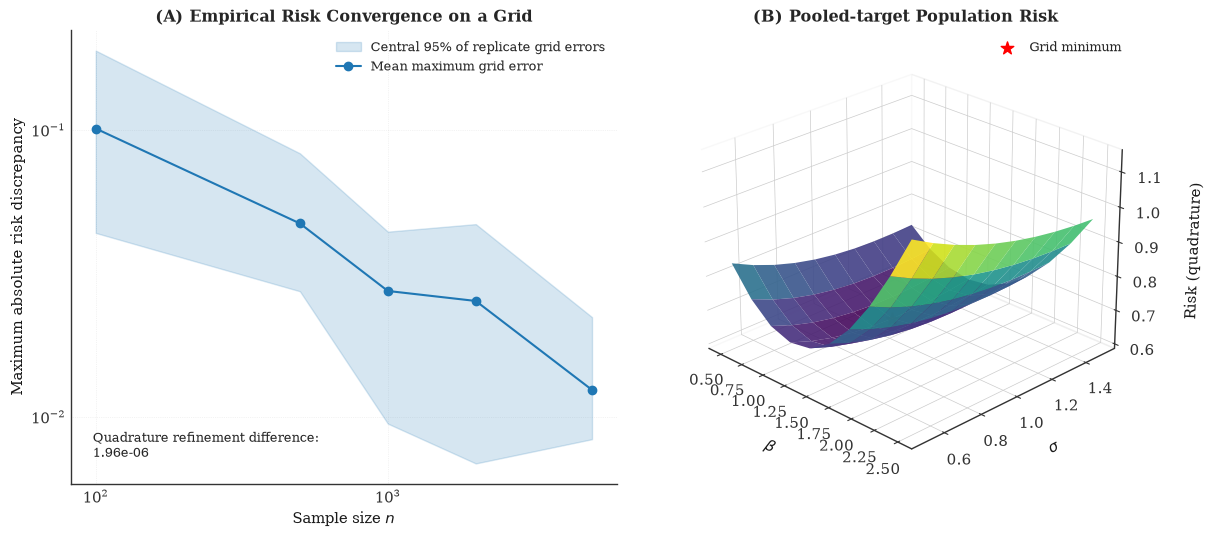

In [ ]:
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import roots_hermitenorm, roots_legendre
from tqdm.auto import tqdm

from ensurv.km import kaplan_meier_batched
from ensurv.horizon import apply_tau_restriction
from ensurv.loss import survival_engression_loss

# Data-generating parameters.
BETA_TRUE = 1.5
SIGMA_TRUE = 1.0

# Fixed censoring lower bound and restriction horizon.
C0 = float(np.exp(-1.0))
TAU = float(np.exp(2.0))
CENSOR_LOG_SD = 2.0

# Compact candidate parameter space.
BETA_GRID = np.linspace(0.5, 2.5, 10)
SIGMA_GRID = np.linspace(0.5, 1.5, 10)

# Population-reference quadrature settings.
# Each tuple gives orders for covariates, log-times, and censoring integration.
REFERENCE_ORDERS = (
    (40, 64, 48),
    (80, 128, 96),
    (160, 256, 192),
)
REFERENCE_STABILITY_TOL = 1e-6
Z_LOWER = -18.0


def censor_survival(times):
    """P(C >= t) for C = c0 + exp(N(0, CENSOR_LOG_SD**2))."""
    times = np.asarray(times, dtype=np.float64)
    result = np.ones_like(times)
    above = times > C0
    result[above] = norm.sf(
        np.log(times[above] - C0) / CENSOR_LOG_SD
    )
    return result


def normal_absolute_distance(z, mean, sigma):
    """E|z-U| for U ~ N(mean, sigma**2), supporting broadcasting."""
    difference = z - mean
    standardized = difference / sigma
    return (
        2.0 * sigma * norm.pdf(standardized)
        + difference
        * (norm.cdf(standardized) - norm.sf(standardized))
    )


def interval_quadrature(left, right, order):
    nodes, weights = roots_legendre(order)
    half = 0.5 * (right - left)
    return left + half * (nodes + 1.0), half * weights


def population_risk_surface(beta_grid, sigma_grid, orders):
    """
    Deterministic quadrature for the POOLED-TARGET population risk.

    For z < a = log(tau), the pseudo-complete conditional density is

        f_Z(z|x) G(exp(z)) + f_Z_marg(z) H_x(z),

    where

        H_x(z) = integral_{c0}^{exp(z)}
                  S_T(c|x) f_C(c) / S_T_marg(c) dc

    and H_x(z)=0 for z <= log(c0).

    The terminal mass at a is

        S_T(tau|x) G(tau) + S_T_marg(tau) H_x(a).

    Predictions are uncapped normal draws. Their energy contribution
    is exactly -sigma/sqrt(pi).
    """
    nx, nz, nc = orders
    a = np.log(TAU)
    lower_c = np.log(C0)
    sigma_marg = np.sqrt(BETA_TRUE**2 + SIGMA_TRUE**2)

    if Z_LOWER >= min(lower_c, 0.0):
        raise ValueError("Z_LOWER must be below both log(c0) and zero.")

    # Standard-normal integration in x.
    x, x_weights = roots_hermitenorm(nx)
    x_weights = x_weights / np.sqrt(2.0 * np.pi)

    # Split the event-time integral at log(c0).
    z_left, w_left = interval_quadrature(Z_LOWER, lower_c, nz)
    z_right, w_right = interval_quadrature(lower_c, a, nz)
    z = np.concatenate((z_left, z_right))
    z_weights = np.concatenate((w_left, w_right))

    # Calculate H_x(z) and H_x(a).
    endpoints = np.append(z, a)
    H = np.zeros((nx, len(endpoints)), dtype=np.float64)
    active = endpoints > lower_c

    c_nodes, c_weights = roots_legendre(nc)
    half_width = 0.5 * (endpoints[active] - lower_c)
    log_c = (
        lower_c
        + half_width[:, None] * (c_nodes[None, :] + 1.0)
    )
    c = np.exp(log_c)
    shifted_c = c - C0

    # Censoring density under the change of variables c=exp(log_c).
    censor_log_density = (
        c / (CENSOR_LOG_SD * shifted_c)
        * norm.pdf(np.log(shifted_c) / CENSOR_LOG_SD)
    )
    integration_weights = (
        half_width[:, None]
        * c_weights[None, :]
        * censor_log_density
    )

    conditional_survival = norm.sf(
        (
            log_c[None, :, :]
            - BETA_TRUE * x[:, None, None]
        ) / SIGMA_TRUE
    )
    marginal_survival = norm.sf(log_c / sigma_marg)

    H[:, active] = np.sum(
        conditional_survival
        / marginal_survival[None, :, :]
        * integration_weights[None, :, :],
        axis=2,
    )

    # Pseudo-complete density before the horizon.
    conditional_density = (
        norm.pdf(
            (z[None, :] - BETA_TRUE * x[:, None]) / SIGMA_TRUE
        ) / SIGMA_TRUE
    )
    marginal_density = norm.pdf(z / sigma_marg) / sigma_marg

    pseudo_density = (
        conditional_density * censor_survival(np.exp(z))[None, :]
        + marginal_density[None, :] * H[:, :-1]
    )

    # Pseudo-complete terminal mass.
    G_tau = float(censor_survival(np.array([TAU]))[0])
    terminal_mass = (
        norm.sf((a - BETA_TRUE * x) / SIGMA_TRUE) * G_tau
        + norm.sf(a / sigma_marg) * H[:, -1]
    )

    density_weights = (
        x_weights[:, None] * z_weights[None, :] * pseudo_density
    )
    terminal_weights = x_weights * terminal_mass

    # Do not renormalize: retain normalization error as a diagnostic.
    integrated_mass = density_weights.sum() + terminal_weights.sum()
    mass_error = abs(integrated_mass - 1.0)

    surface = np.empty((len(beta_grid), len(sigma_grid)))
    for i, beta in enumerate(beta_grid):
        mean = beta * x[:, None]
        for j, sigma in enumerate(sigma_grid):
            first_term = np.sum(
                density_weights
                * normal_absolute_distance(z[None, :], mean, sigma)
            )
            terminal_term = np.sum(
                terminal_weights
                * normal_absolute_distance(a, beta * x, sigma)
            )
            surface[i, j] = (
                first_term + terminal_term - sigma / np.sqrt(np.pi)
            )

    # Uniform bound on the omitted event contribution below Z_LOWER.
    # Completion adds no mass there because Z_LOWER < log(c0).
    tail_probability = norm.cdf(Z_LOWER / sigma_marg)
    tail_bound = (
        sigma_marg * norm.pdf(Z_LOWER / sigma_marg)
        + np.max(np.abs(beta_grid)) * np.sqrt(tail_probability)
        + np.max(sigma_grid)
        * np.sqrt(2.0 / np.pi) * tail_probability
    )

    return surface, mass_error, tail_bound


def compute_population_reference(beta_grid, sigma_grid):
    """
    Refine deterministic quadrature.

    Successive surface differences are numerical stability diagnostics,
    not certified bounds on the remaining quadrature error.
    """
    previous = None
    refinement_difference = np.inf

    for orders in REFERENCE_ORDERS:
        reference, mass_error, tail_bound = population_risk_surface(
            beta_grid, sigma_grid, orders
        )

        if previous is not None:
            refinement_difference = np.max(np.abs(reference - previous))

        print(
            f"Reference orders={orders}: "
            f"mass error={mass_error:.3e}, "
            f"refinement difference={refinement_difference:.3e}, "
            f"omitted-tail bound={tail_bound:.3e}"
        )

        if (
            previous is not None
            and refinement_difference <= REFERENCE_STABILITY_TOL
            and mass_error <= REFERENCE_STABILITY_TOL
        ):
            break

        previous = reference.copy()

    if (
        refinement_difference > REFERENCE_STABILITY_TOL
        or mass_error > REFERENCE_STABILITY_TOL
    ):
        warnings.warn(
            "Reference stability goal was not reached. Increase "
            "REFERENCE_ORDERS before interpreting small discrepancies."
        )

    return reference, refinement_difference, mass_error, tail_bound, orders


def generate_data(n, rng):
    X = rng.standard_normal(n)
    event_noise = rng.standard_normal(n)
    Z = BETA_TRUE * X + SIGMA_TRUE * event_noise
    T = np.exp(Z)

    # Independent censoring with a fixed positive lower bound.
    C = C0 + np.exp(rng.normal(0.0, CENSOR_LOG_SD, n))

    Y = np.minimum(T, C)
    delta = (T <= C).astype(np.int64)
    return X, Y, delta


def compute_empirical_surface(
    X, Y, delta, beta_grid, sigma_grid,
    bootstrap_rng, noise_rng, B, m, device,
    data_batch_size=512, km_batch_size=4,
):
    """
    Compute the actual finite-m empirical criterion.

    Bootstrap curves and observation-specific noises are generated ONCE
    per dataset and held fixed across every candidate parameter.
    Chunking only controls memory; weighted chunk losses reproduce the
    full-data criterion.
    """
    n = len(Y)

    X_t = torch.as_tensor(X, dtype=torch.float64, device=device)
    Y_original = torch.as_tensor(Y, dtype=torch.float64, device=device)
    delta_original = torch.as_tensor(
        delta, dtype=torch.float64, device=device
    )

    Y_tau, D = apply_tau_restriction(Y_original, delta_original, TAU)

    indices = bootstrap_rng.integers(
        0, n, size=(B, n), dtype=np.int64
    )
    km_curves = kaplan_meier_batched(
        Y_original,
        delta_original,
        indices,
        close_tail=True,
        device=device,
        tau=TAU,
        bootstrap_batch_size=km_batch_size,
    )

    # IID across observations and draws; common across parameter values.
    fixed_noise = torch.as_tensor(
        noise_rng.standard_normal((n, m)),
        dtype=torch.float64,
        device=device,
    )

    surface = np.empty((len(beta_grid), len(sigma_grid)))

    with torch.inference_mode():
        for i, beta in enumerate(beta_grid):
            for j, sigma in enumerate(sigma_grid):
                total = torch.zeros(
                    (), dtype=torch.float64, device=device
                )

                for start in range(0, n, data_batch_size):
                    end = min(start + data_batch_size, n)

                    # RAW generated log-times: no horizon clamp.
                    predictions = (
                        beta * X_t[start:end, None]
                        + sigma * fixed_noise[start:end]
                    )

                    loss = survival_engression_loss(
                        predictions,
                        Y_tau[start:end],
                        D[start:end],
                        km_curves,
                        lambda_energy=0.5,
                    )
                    total += loss * ((end - start) / n)

                surface[i, j] = total.item()

    return surface


def run_simulation(
    sample_sizes=(100, 500, 1000, 2000, 5000),
    n_repetitions=10,
    B=25,
    m=50,
    seed=42,
    device=None,
    data_batch_size=512,
    km_batch_size=4,
):
    if n_repetitions < 2 or B < 1 or m < 2:
        raise ValueError("Require repetitions >= 2, B >= 1 and m >= 2.")
    if data_batch_size < 1 or km_batch_size < 1:
        raise ValueError("Batch sizes must be positive.")

    sample_sizes = np.asarray(sample_sizes, dtype=int)
    if (
        sample_sizes.ndim != 1
        or len(sample_sizes) == 0
        or (sample_sizes < 1).any()
        or (np.diff(sample_sizes) <= 0).any()
    ):
        raise ValueError("Sample sizes must be positive and increasing.")

    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)

    seed_data, seed_bootstrap, seed_noise = (
        np.random.SeedSequence(seed).spawn(3)
    )
    data_rng = np.random.default_rng(seed_data)
    bootstrap_rng = np.random.default_rng(seed_bootstrap)
    noise_rng = np.random.default_rng(seed_noise)

    reference, refinement_difference, mass_error, tail_bound, orders = (
        compute_population_reference(BETA_GRID, SIGMA_GRID)
    )

    sigma_marg = np.sqrt(BETA_TRUE**2 + SIGMA_TRUE**2)
    followup_probability = (
        norm.sf(np.log(TAU) / sigma_marg)
        * float(censor_survival(np.array([TAU]))[0])
    )
    print(f"\nDevice: {device}")
    print(f"Fixed c0={C0:.6f}, tau={TAU:.6f}")
    print(f"Population P(Y >= tau)={followup_probability:.6f}")
    print(f"Fixed m={m}, B={B}, repetitions={n_repetitions}\n")

    shape = (len(sample_sizes), n_repetitions)
    grid_errors = np.empty(shape)
    followup_counts = np.empty(shape, dtype=np.int64)
    empirical_surfaces = np.empty(
        shape + (len(BETA_GRID), len(SIGMA_GRID))
    )

    for size_index, n in enumerate(sample_sizes):
        for repetition in tqdm(
            range(n_repetitions), desc=f"n={n}", leave=False
        ):
            X, Y, delta = generate_data(n, data_rng)
            followup_counts[size_index, repetition] = np.count_nonzero(
                Y >= TAU
            )

            # Retain every dataset; do not condition on positive
            # observed follow-up at the horizon.
            empirical = compute_empirical_surface(
                X, Y, delta,
                BETA_GRID, SIGMA_GRID,
                bootstrap_rng, noise_rng,
                B=B, m=m, device=device,
                data_batch_size=data_batch_size,
                km_batch_size=km_batch_size,
            )

            empirical_surfaces[size_index, repetition] = empirical
            grid_errors[size_index, repetition] = np.max(
                np.abs(empirical - reference)
            )

        print(
            f"n={n:<6d} "
            f"mean maximum grid error="
            f"{grid_errors[size_index].mean():.6f} | "
            f"no-followup datasets="
            f"{np.count_nonzero(followup_counts[size_index] == 0)}"
            f"/{n_repetitions}"
        )

    return {
        "sample_sizes": sample_sizes,
        "grid_errors": grid_errors,
        "empirical_surfaces": empirical_surfaces,
        "reference_surface": reference,
        "beta_grid": BETA_GRID,
        "sigma_grid": SIGMA_GRID,
        "quadrature_refinement_difference": refinement_difference,
        "quadrature_mass_error": mass_error,
        "omitted_tail_bound": tail_bound,
        "reference_orders": np.asarray(orders),
        "followup_counts": followup_counts,
        "followup_probability": followup_probability,
        "c0": C0,
        "tau": TAU,
        "beta_true": BETA_TRUE,
        "sigma_true": SIGMA_TRUE,
        "censor_log_sd": CENSOR_LOG_SD,
        "m": m,
        "B": B,
        "seed": seed,
    }


def plot_simulation(results):
    n = results["sample_sizes"]
    errors = results["grid_errors"]
    means = errors.mean(axis=1)
    lower = np.quantile(errors, 0.025, axis=1)
    upper = np.quantile(errors, 0.975, axis=1)

    fig = plt.figure(figsize=(12, 5.5))
    ax1 = fig.add_subplot(1, 2, 1)

    ax1.fill_between(
        n, lower, upper, color="#1f77b4", alpha=0.18,
        label="Central 95% of replicate grid errors",
    )
    ax1.plot(
        n, means, "o-", color="#1f77b4",
        label="Mean maximum grid error",
    )
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel(r"Sample size $n$")
    ax1.set_ylabel("Maximum absolute risk discrepancy")
    ax1.set_title("(A) Empirical Risk Convergence on a Grid")
    ax1.grid(True, linestyle=":", alpha=0.45)
    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)
    ax1.legend(frameon=False)

    ax1.text(
        0.04, 0.06,
        "Quadrature refinement difference:\n"
        f"{results['quadrature_refinement_difference']:.2e}",
        transform=ax1.transAxes,
        fontsize=9,
    )

    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    beta_mesh, sigma_mesh = np.meshgrid(
        results["beta_grid"], results["sigma_grid"], indexing="ij"
    )
    reference = results["reference_surface"]

    ax2.plot_surface(
        beta_mesh, sigma_mesh, reference,
        cmap="viridis", edgecolor="none", alpha=0.9,
    )

    i_min, j_min = np.unravel_index(
        np.argmin(reference), reference.shape
    )
    ax2.scatter(
        beta_mesh[i_min, j_min],
        sigma_mesh[i_min, j_min],
        reference[i_min, j_min],
        color="red", marker="*", s=90, label="Grid minimum",
    )

    ax2.set_xlabel(r"$\beta$", labelpad=8)
    ax2.set_ylabel(r"$\sigma$", labelpad=8)
    ax2.set_zlabel("Risk (quadrature)", labelpad=10)
    ax2.set_title("(B) Pooled-target Population Risk")
    ax2.view_init(elev=25, azim=-45)
    ax2.xaxis.pane.fill = False
    ax2.yaxis.pane.fill = False
    ax2.zaxis.pane.fill = False
    ax2.legend(frameon=False)

    fig.tight_layout()
    fig.savefig("Theorem_2_Simulations.pdf", bbox_inches="tight")
    fig.savefig("Theorem_2_Simulations.png", dpi=300, bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    results = run_simulation(
        n_repetitions=10,      # Increase to 50 for more stable summaries.
        B=25,
        m=50,
        seed=42,
        device="cuda:0",          # Automatic GPU/CPU selection.
        data_batch_size=4096,
        km_batch_size=1000,
    )

    np.savez_compressed("Theorem_2_raw_results.npz", **results)

    errors = results["grid_errors"]
    summary = np.column_stack((
        results["sample_sizes"],
        errors.mean(axis=1),
        errors.std(axis=1, ddof=1),
        np.quantile(errors, 0.025, axis=1),
        np.quantile(errors, 0.975, axis=1),
        (results["followup_counts"] == 0).mean(axis=1),
    ))
    np.savetxt(
        "Theorem_2_summary.csv",
        summary,
        delimiter=",",
        header=(
            "n,mean_grid_error,sd_grid_error,q025,q975,"
            "no_followup_fraction"
        ),
        comments="",
        fmt="%.10g",
    )

    plot_simulation(results)